# SEC Third Down Conversion Stats

SEC Team Stats stats from `sql/analysis/sec_scoring_drive_conversions.sql` and `sql/analysis/sec_team_third_down.sql` .

In [8]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# shared project code (src/cfb): paths, database connection, read_query()
from cfb.config import ROOT, SQL_ANALYSIS_DIR
from cfb.db import engine, read_query



In [9]:
query = (SQL_ANALYSIS_DIR / "sec_team_third_down.sql").read_text()

df = pd.read_sql(query, engine)
df

,team,games,third_down_plays,third_down_pass_plays,third_down_rush_plays,third_down_avg_distance,third_down_avg_yards_gained,third_down_conversion_rate,third_down_pass_conv,third_down_pass_conv_rate,...,drives_per_q3,drives_per_q4,avg_plays_per_drive,avg_plays_per_drive_1st_half,avg_plays_per_drive_2nd_half,avg_plays_per_drive_q1,avg_plays_per_drive_q2,avg_plays_per_drive_q3,avg_plays_per_drive_q4,avg_yards_per_drive
0,Georgia,5,51,31,20,5.53,9.96,0.569,15,0.484,...,3.4,2.6,4.85,4.66,5.07,5.25,4.06,5.59,4.38,38.7
1,LSU,5,78,44,34,6.13,7.01,0.526,22,0.500,...,4.0,2.4,6.50,6.69,6.31,5.83,7.79,5.70,7.33,42.8
2,Texas,4,60,37,23,6.58,5.88,0.500,15,0.405,...,3.5,2.0,6.52,6.23,6.82,5.40,6.92,5.79,8.63,34.5
3,Alabama,5,57,35,22,7.23,9.77,0.491,14,0.400,...,3.2,2.6,5.69,5.69,5.69,5.64,5.73,5.00,6.54,40.5
4,Mississippi State,5,64,40,24,7.25,6.42,0.469,14,0.350,...,3.0,2.4,5.92,5.61,6.30,5.79,5.47,6.33,6.25,40.9
5,Auburn,5,75,47,28,7.11,5.47,0.467,18,0.383,...,2.4,2.6,6.02,4.82,7.60,4.06,5.63,8.83,6.46,34.2
6,Florida,5,61,36,25,8.38,8.08,0.459,15,0.417,...,3.0,2.6,6.04,6.55,5.50,6.93,6.20,5.27,5.77,43.0
7,South Carolina,5,71,42,29,6.82,7.32,0.451,14,0.333,...,2.8,2.6,6.08,6.22,5.93,7.06,5.27,6.29,5.54,40.2
8,Missouri,5,67,48,19,7.30,6.64,0.448,23,0.479,...,3.2,3.2,5.27,5.63,4.91,7.38,4.42,5.81,4.00,34.9
9,Arkansas,5,73,48,25,7.47,6.16,0.438,17,0.354,...,2.4,2.4,6.33,5.74,7.08,5.80,5.69,7.08,7.08,30.4


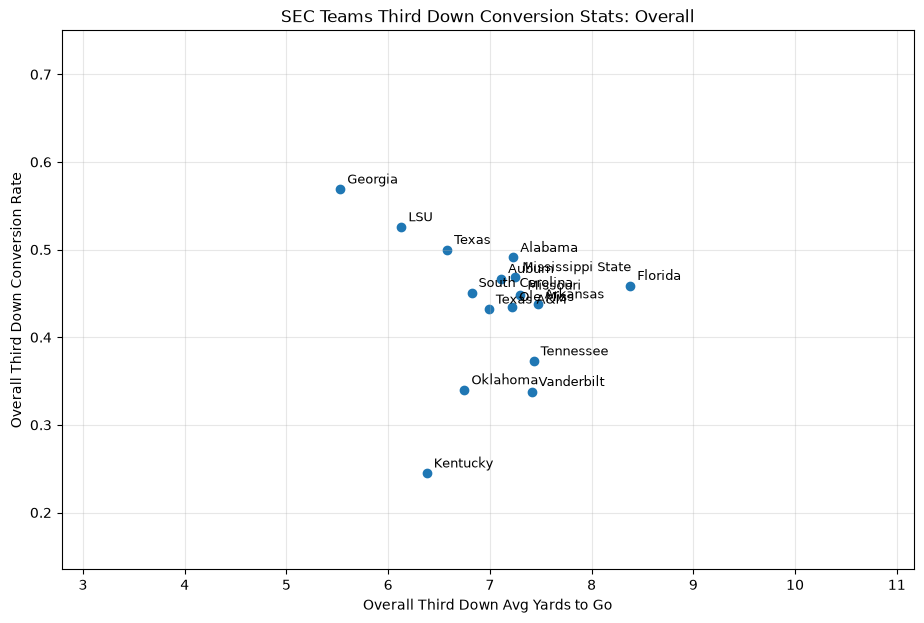

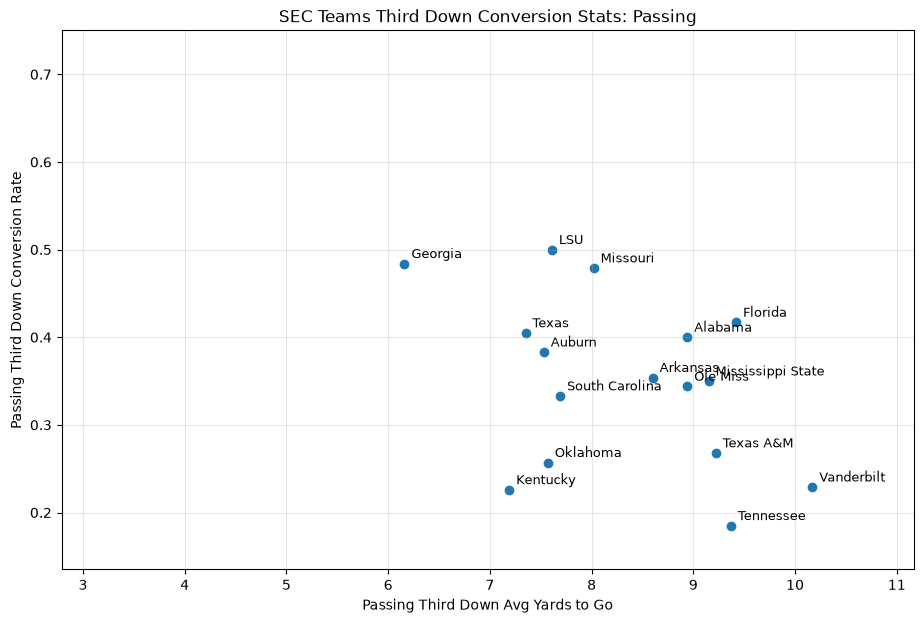

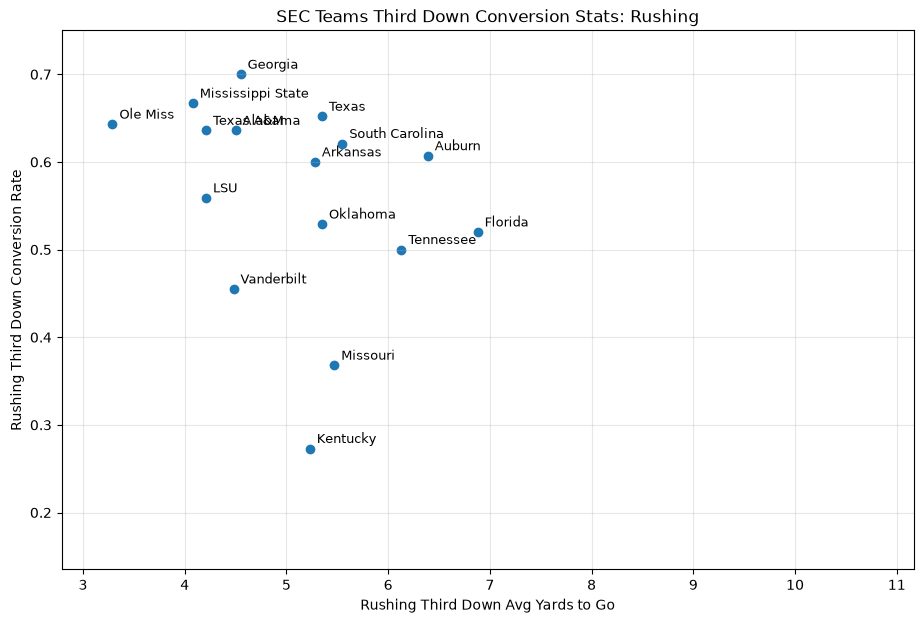

In [10]:
charts = [
    ('third_down_avg_distance',   'third_down_conversion_rate', 'Overall'),
    ('third_down_pass_avg_to_go', 'third_down_pass_conv_rate',  'Passing'),
    ('third_down_rush_avg_to_go', 'third_down_rush_conv_rate',  'Rushing'),
]

# same axis ranges on all three charts so the splits are directly comparable
x_cols = [x for x, _, _ in charts]
y_cols = [y for _, y, _ in charts]
x_min, x_max = df[x_cols].min().min() - 0.5, df[x_cols].max().max() + 1.0
y_min, y_max = df[y_cols].min().min() - 0.05, df[y_cols].max().max() + 0.05

for x_col, y_col, label in charts:
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.scatter(df[x_col], df[y_col])

    for _, row in df.iterrows():
        ax.annotate(row['team'], (row[x_col], row[y_col]),
                    xytext=(5, 4), textcoords='offset points', fontsize=9)

    ax.set_xlabel(f'{label} Third Down Avg Yards to Go')
    ax.set_ylabel(f'{label} Third Down Conversion Rate')
    ax.set_title(f'SEC Teams Third Down Conversion Stats: {label}')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.3)
    plt.show()

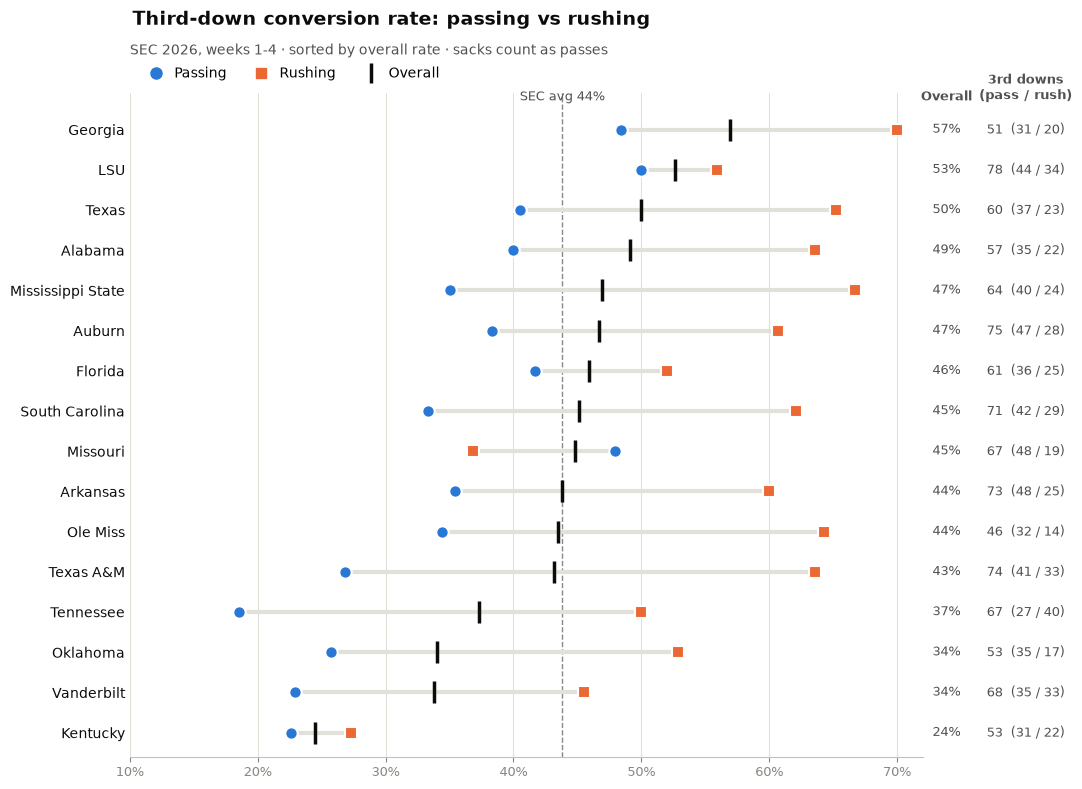

In [11]:
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

# colors: passing / rushing are a colorblind-safe pair; overall is plain ink
PASS, RUSH = '#2a78d6', '#eb6834'
INK, SECONDARY, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'

plot_df = df.sort_values('third_down_conversion_rate')   # best team ends up on top
y = np.arange(len(plot_df))
pass_rate = plot_df['third_down_pass_conv_rate']
rush_rate = plot_df['third_down_rush_conv_rate']
overall = plot_df['third_down_conversion_rate']
sec_avg = (df['third_down_conversion_rate'] * df['third_down_plays']).sum() / df['third_down_plays'].sum()

fig, ax = plt.subplots(figsize=(11, 8))

# line between each team's passing and rushing rate = the gap between them
ax.hlines(y, np.minimum(pass_rate, rush_rate), np.maximum(pass_rate, rush_rate),
          color=GRID, linewidth=3, zorder=1)
ax.scatter(pass_rate, y, s=80, marker='o', color=PASS, edgecolor='white', linewidth=1.5, zorder=3)
ax.scatter(rush_rate, y, s=70, marker='s', color=RUSH, edgecolor='white', linewidth=1.5, zorder=3)
ax.scatter(overall, y, s=260, marker='|', color=INK, linewidths=2.5, zorder=4)

# SEC average reference line
ax.axvline(sec_avg, color=MUTED, linestyle='--', linewidth=1, zorder=0)
ax.text(sec_avg, len(plot_df) - 0.35, f'SEC avg {sec_avg:.0%}', color=SECONDARY,
        fontsize=9, ha='center', va='bottom')

# right-hand columns: overall rate, and total 3rd down plays (pass / rush)
col_overall, col_plays = 1.03, 1.13
header_y = len(plot_df) - 0.35
ax.text(col_overall, header_y, 'Overall', transform=ax.get_yaxis_transform(),
        fontsize=9, color=SECONDARY, fontweight='bold', va='bottom', ha='center')
ax.text(col_plays, header_y, '3rd downs\n(pass / rush)', transform=ax.get_yaxis_transform(),
        fontsize=9, color=SECONDARY, fontweight='bold', va='bottom', ha='center')
for yi, (_, row) in zip(y, plot_df.iterrows()):
    ax.text(col_overall, yi, f"{row['third_down_conversion_rate']:.0%}",
            transform=ax.get_yaxis_transform(), fontsize=9, color=SECONDARY,
            va='center', ha='center')
    ax.text(col_plays, yi,
            f"{row['third_down_plays']}  ({row['third_down_pass_plays']} / {row['third_down_rush_plays']})",
            transform=ax.get_yaxis_transform(), fontsize=9, color=SECONDARY,
            va='center', ha='center')

# axes: team names on the left, light vertical gridlines, no box
ax.set_yticks(y)
ax.set_yticklabels(plot_df['team'], fontsize=10, color=INK)
ax.set_ylim(-0.6, len(plot_df) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0.10, 0.72)
ax.tick_params(axis='x', colors=MUTED, labelsize=9)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#c3c2b7')

# title, subtitle, legend
fig.suptitle('Third-down conversion rate: passing vs rushing', x=0.125, ha='left',
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('SEC 2026, weeks 1-4 · sorted by overall rate · sacks count as passes',
             loc='left', fontsize=10, color=SECONDARY, pad=28)
ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='', markersize=8, color=PASS, label='Passing'),
    Line2D([], [], marker='s', linestyle='', markersize=7, color=RUSH, label='Rushing'),
    Line2D([], [], marker='|', linestyle='', markersize=14, markeredgewidth=2.5, color=INK, label='Overall'),
], loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10,
   handletextpad=0.3, columnspacing=1.5)

plt.tight_layout()
plt.show()

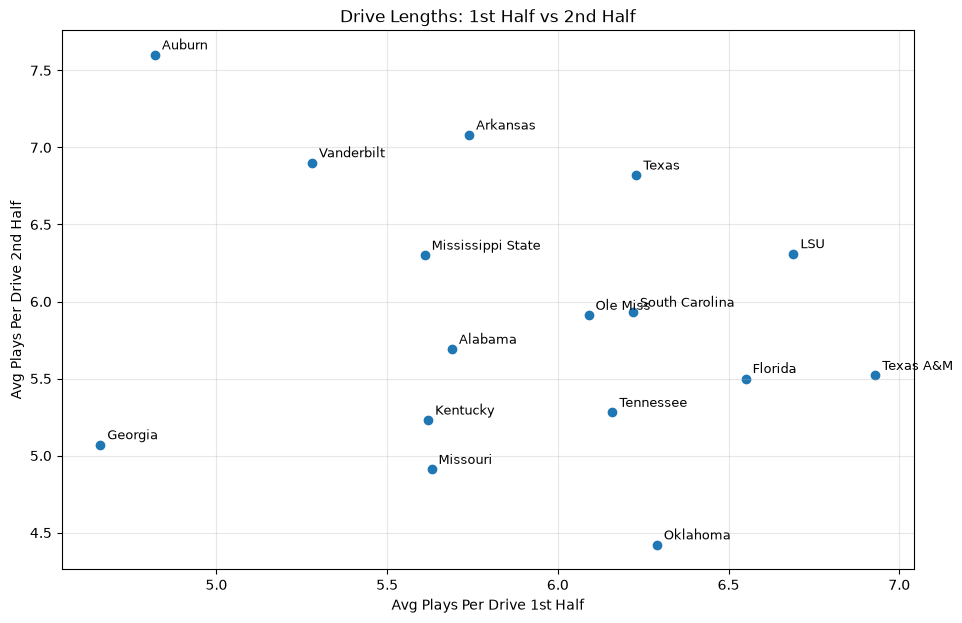

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(df['avg_plays_per_drive_1st_half'], df['avg_plays_per_drive_2nd_half'])

for _, row in df.iterrows():
    ax.annotate(row['team'], (row['avg_plays_per_drive_1st_half'], row['avg_plays_per_drive_2nd_half']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)

ax.set_xlabel('Avg Plays Per Drive 1st Half')
ax.set_ylabel('Avg Plays Per Drive 2nd Half')
ax.set_title('Drive Lengths: 1st Half vs 2nd Half')
ax.grid(alpha=0.3)
plt.show()

In [13]:
query = (SQL_ANALYSIS_DIR / "sec_scoring_drive_conversions.sql").read_text()

scoring_drives = pd.read_sql(query, engine)
scoring_drives

,team,drives,scoring_drives,td_drives,fg_drives,scoring_drive_rate,sd_third_att,sd_third_conv,sd_third_conv_rate,sd_fourth_att,...,td_drive_conversions_per_drive,fg_drive_conversions_per_drive,sd_pct_needing_a_conversion,sd_pct_no_third_down_faced,nsd_third_att,nsd_third_conv,nsd_third_conv_rate,nsd_fourth_att,nsd_fourth_conv,nsd_conversions_per_drive
0,Arkansas,55,18,11,7,0.327,31.0,20.0,0.645,4.0,...,1.55,1.00,0.833,0.056,42.0,12.0,0.286,6.0,0.0,0.32
1,Vanderbilt,53,18,13,5,0.340,28.0,14.0,0.500,9.0,...,1.38,1.00,0.833,0.111,40.0,9.0,0.225,8.0,2.0,0.31
2,Texas,44,22,15,7,0.500,36.0,24.0,0.667,4.0,...,1.33,1.14,0.727,0.136,24.0,6.0,0.250,3.0,0.0,0.27
3,Auburn,58,19,15,4,0.328,25.0,17.0,0.680,4.0,...,1.33,0.25,0.737,0.158,50.0,18.0,0.360,5.0,1.0,0.49
4,Texas A&M,58,25,17,8,0.431,37.0,22.0,0.595,5.0,...,1.29,0.63,0.560,0.240,37.0,10.0,0.270,10.0,3.0,0.39
5,LSU,64,33,28,5,0.516,37.0,29.0,0.784,4.0,...,1.11,0.40,0.667,0.242,41.0,12.0,0.293,6.0,4.0,0.52
6,South Carolina,60,29,21,8,0.483,38.0,22.0,0.579,7.0,...,0.95,1.13,0.759,0.172,33.0,10.0,0.303,6.0,1.0,0.35
7,Oklahoma,47,14,10,4,0.298,17.0,12.0,0.706,1.0,...,1.20,0.25,0.643,0.143,36.0,6.0,0.167,3.0,0.0,0.18
8,Mississippi State,60,33,26,7,0.550,37.0,25.0,0.676,5.0,...,0.96,0.71,0.545,0.333,27.0,5.0,0.185,2.0,1.0,0.22
9,Florida,57,35,28,7,0.614,37.0,23.0,0.622,6.0,...,0.79,1.00,0.543,0.371,24.0,5.0,0.208,3.0,0.0,0.23


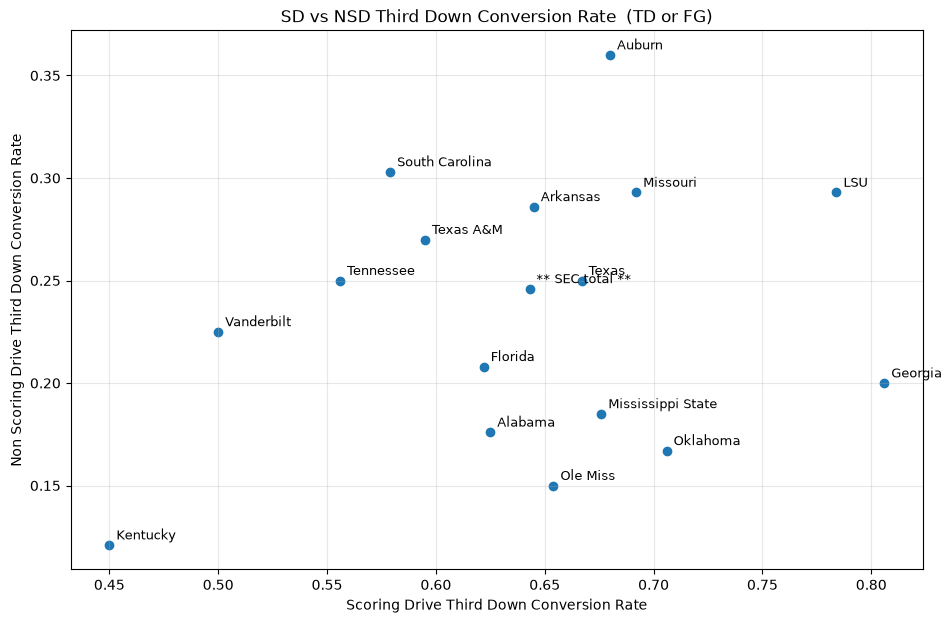

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(scoring_drives['sd_third_conv_rate'], scoring_drives['nsd_third_conv_rate'])

for _, row in scoring_drives.iterrows():
    ax.annotate(row['team'], (row['sd_third_conv_rate'], row['nsd_third_conv_rate']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)

ax.set_xlabel('Scoring Drive Third Down Conversion Rate')
ax.set_ylabel('Non Scoring Drive Third Down Conversion Rate')
ax.set_title('SD vs NSD Third Down Conversion Rate  (TD or FG)')
ax.grid(alpha=0.3)
plt.show()